# Heart Failure Prediction: Comparative Analysis of ML Models
**Assignment No. 2: Machine Learning (Project-Based)**

Dataset: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction (file: `heart.csv`)

Problem: predict whether a patient has heart disease (`HeartDisease` = 1) from clinical measurements.

Workflow: EDA → leakage-free preprocessing → 3 models → evaluation → tuning → ensembles → save and reload-test the final model.

**Run this notebook on your own PC (not on Kaggle)** so the machine that saves the model is the one that loads it.

## 1. Setup

In [1]:
import os, glob, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

RANDOM_STATE = 42
TARGET = "HeartDisease"
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Load the dataset
Put `heart.csv` in the same folder as this notebook (download it from the Kaggle link above).

In [2]:
if os.path.exists("heart.csv"):
    CSV = "heart.csv"
else:
    found = glob.glob("/kaggle/input/**/heart.csv", recursive=True)
    if not found:
        raise FileNotFoundError("heart.csv not found. Download it from Kaggle and put it next to this notebook.")
    CSV = found[0]
df = pd.read_csv(CSV)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Exploratory Data Analysis

In [3]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nTarget distribution:\n", df[TARGET].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Duplicate rows: 0
Missing values per column:
 Series([], dtype: int64)

Target distribution:
 HeartDisease
1    508
0    410
Name: count, dtype: int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [5]:
# Hidden missing values: physiologically impossible zeros
print("Cholesterol == 0:", (df["Cholesterol"] == 0).sum())
print("RestingBP   == 0:", (df["RestingBP"] == 0).sum())

Cholesterol == 0: 172
RestingBP   == 0: 1


In [6]:
# A rule-based fix (zero means 'not recorded'), not learned from data, so it cannot leak.
# The resulting NaNs are imputed later inside the pipeline, using training data only.
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)
print(df[["Cholesterol", "RestingBP"]].isna().sum())

Cholesterol    172
RestingBP        1
dtype: int64


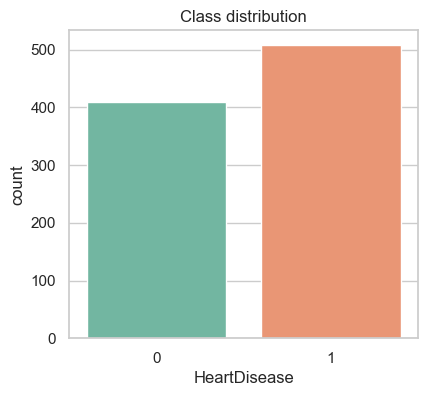

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.countplot(data=df, x=TARGET, ax=ax, palette="Set2")
ax.set_title("Class distribution")
plt.savefig("results/class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
print(df[TARGET].value_counts(normalize=True).round(3))

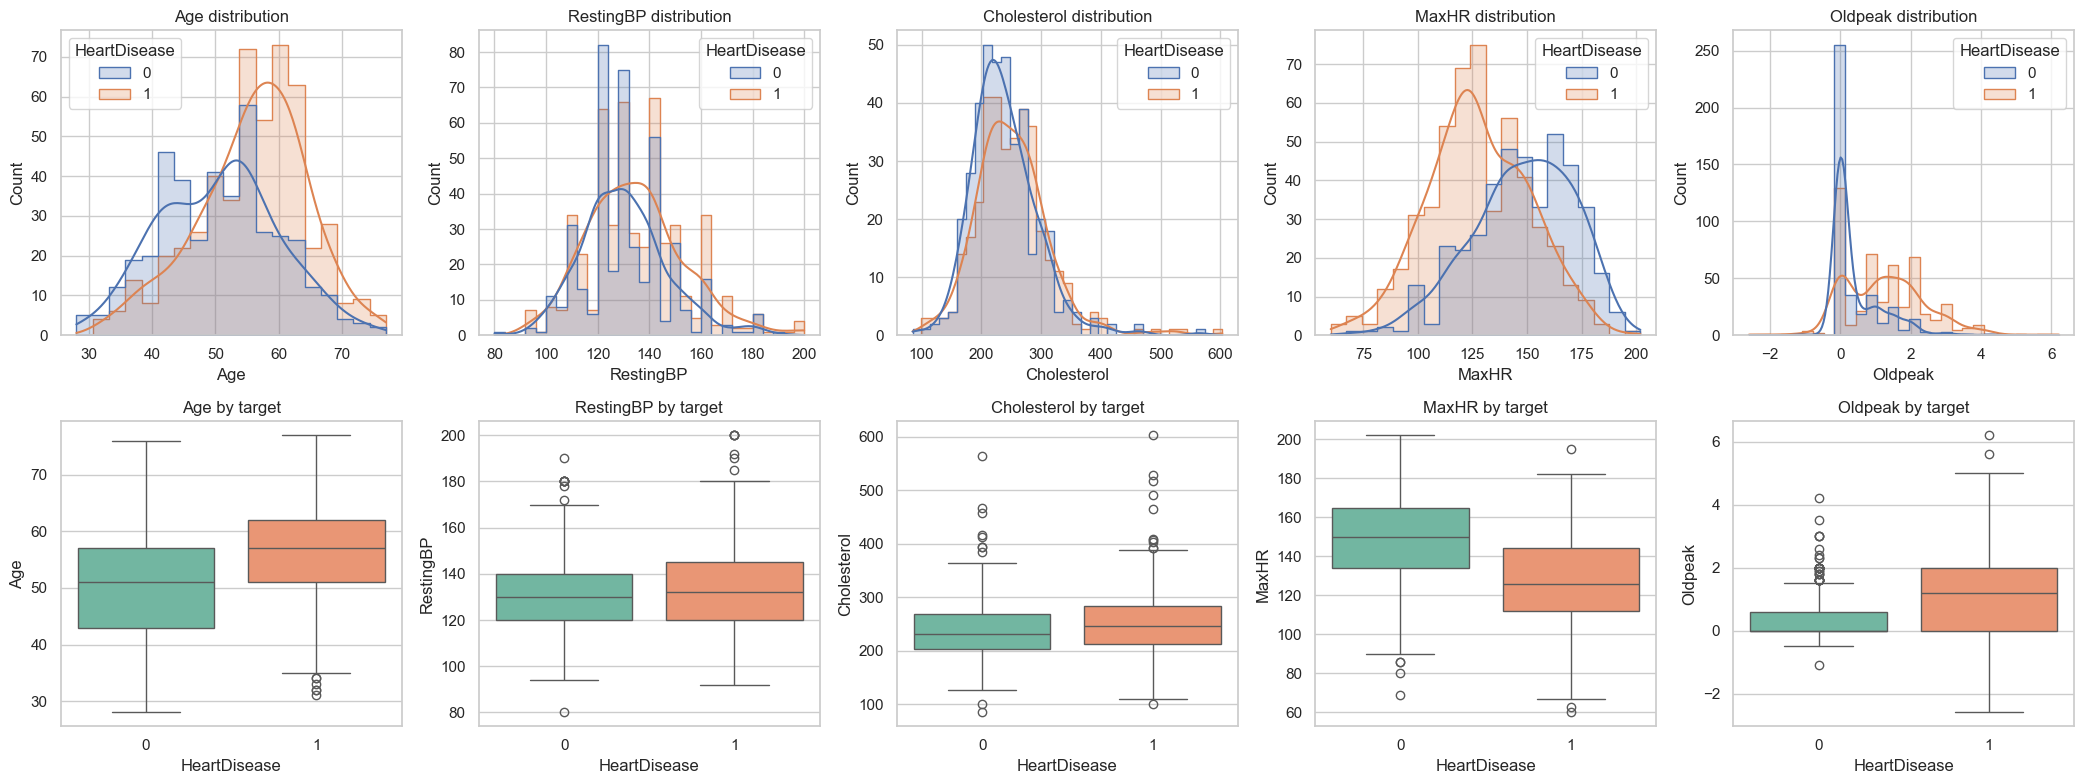

In [8]:
num_eda = [c for c in df.columns if c != TARGET and pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 2]
fig, axes = plt.subplots(2, len(num_eda), figsize=(4.2 * len(num_eda), 8))
for i, c in enumerate(num_eda):
    sns.histplot(data=df, x=c, hue=TARGET, kde=True, ax=axes[0, i], element="step")
    axes[0, i].set_title(f"{c} distribution")
    sns.boxplot(data=df, x=TARGET, y=c, ax=axes[1, i], palette="Set2")
    axes[1, i].set_title(f"{c} by target")
plt.tight_layout(); plt.savefig("results/numeric_eda.png", dpi=150); plt.show()

In [9]:
# IQR outlier report (values are kept; they are plausible clinical readings)
for c in num_eda:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    print(f"{c}: {((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()} IQR outliers")

Age: 0 IQR outliers
RestingBP: 27 IQR outliers
Cholesterol: 23 IQR outliers
MaxHR: 2 IQR outliers
Oldpeak: 16 IQR outliers


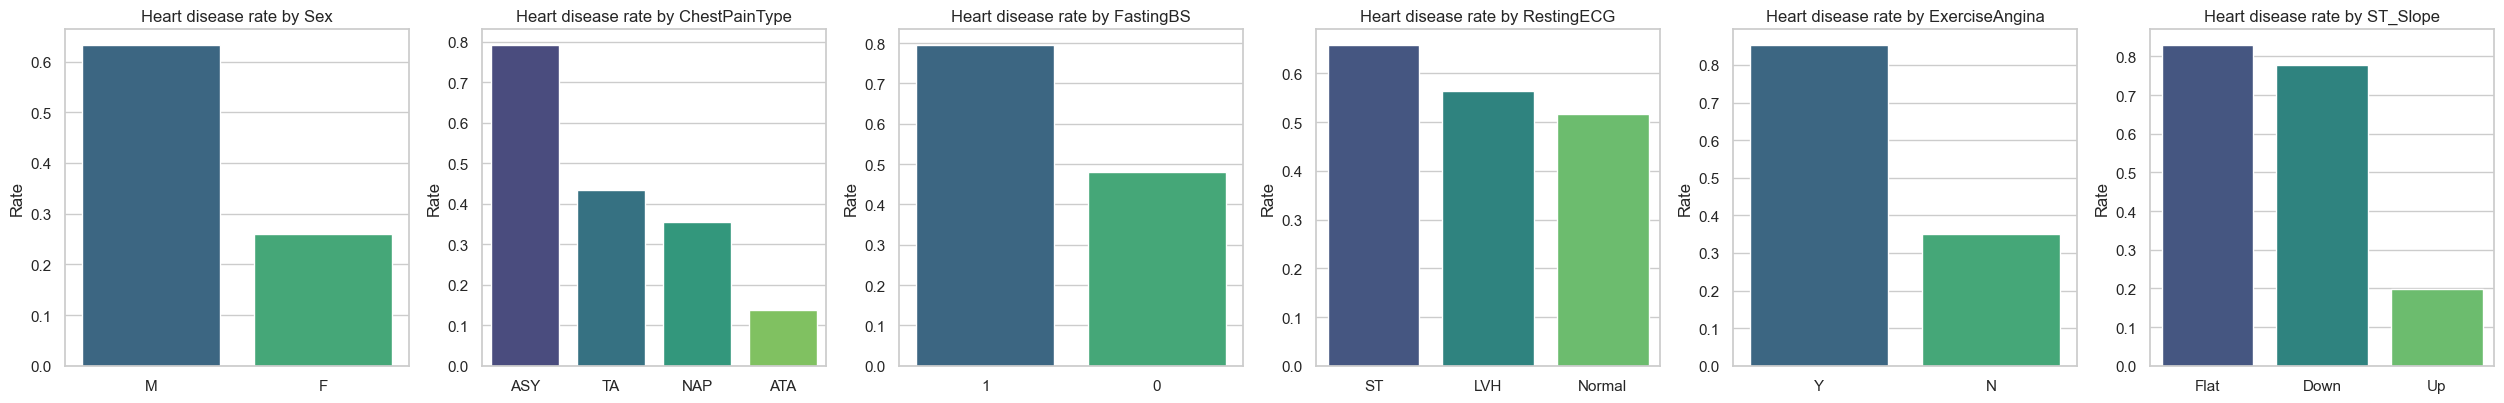

In [10]:
cat_eda = [c for c in df.columns if c != TARGET and (not pd.api.types.is_numeric_dtype(df[c]) or df[c].nunique() <= 2)]
fig, axes = plt.subplots(1, len(cat_eda), figsize=(4.2 * len(cat_eda), 4.2))
for ax, c in zip(np.atleast_1d(axes), cat_eda):
    rate = df.groupby(c)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Heart disease rate by {c}"); ax.set_ylabel("Rate"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("results/categorical_eda.png", dpi=150); plt.show()

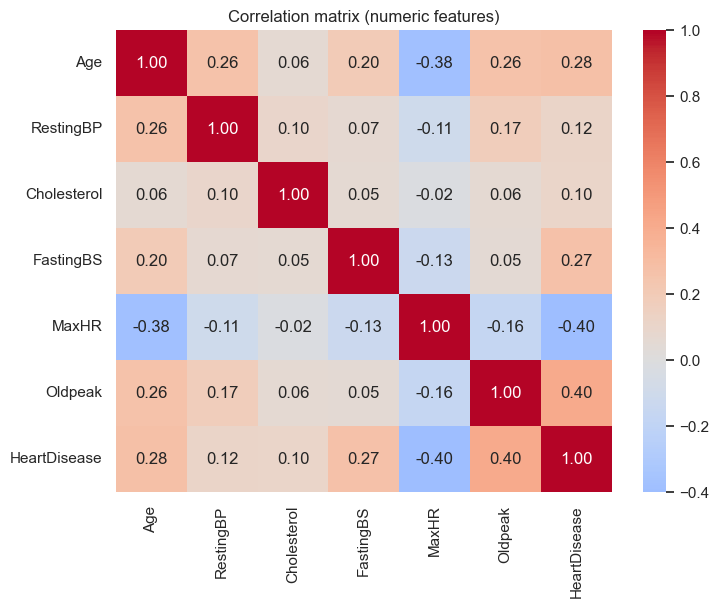

In [11]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)")
plt.savefig("results/correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

### EDA observations (rewrite using what your plots actually show)
- The classes are only mildly imbalanced, so a stratified split is enough and accuracy is meaningful, but recall still matters because missing a sick patient is costly.
- `Cholesterol` and `RestingBP` contained zeros, which are not physiologically possible, so they were treated as missing and imputed.
- Check which features separate the classes in the plots (for example `ST_Slope`, `ExerciseAngina`, `ChestPainType`, `Oldpeak`, `MaxHR`, `Age`).
- Report the duplicate count and the IQR outlier counts printed above.

## 4. Data Preprocessing (leakage-free)
Imputation, scaling and encoding live inside a `Pipeline`, so they are fitted on training data only (and on training folds only during cross-validation).

In [12]:
X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype(int)

# Binary 0/1 numeric columns (e.g. FastingBS) are treated as categorical
for c in X.columns:
    if pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique() <= 2:
        X[c] = X[c].astype(int).astype(str)

cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Numeric:", num_cols); print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Positive rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

Numeric: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Categorical: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Train: (734, 11)  Test: (184, 11)
Positive rate train/test: 0.553 0.554


## 5. Model Development
Three models, same split, same preprocessing, same stratified 5-fold CV.

In [13]:
models = {
    "Logistic Regression": Pipeline([("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", preprocess),
        ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("prep", preprocess),
        ("clf", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                           random_state=RANDOM_STATE))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, model, X_te, y_te):
    pred = model.predict(X_te); proba = model.predict_proba(X_te)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred), "F1-Score": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, proba)}

rows, cv_rows = [], []
for name, m in models.items():
    cv_auc = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": cv_auc.mean(), "CV ROC-AUC (std)": cv_auc.std()})
    m.fit(X_train, y_train)
    rows.append(evaluate(name, m, X_test, y_test))
cv_df = pd.DataFrame(cv_rows).set_index("Model").round(4)
baseline = pd.DataFrame(rows).set_index("Model").round(4)
print(cv_df); print(); print(baseline)
baseline.to_csv("results/baseline_comparison.csv")

                     CV ROC-AUC (mean)  CV ROC-AUC (std)
Model                                                   
Logistic Regression             0.9223            0.0339
Random Forest                   0.9290            0.0253
Gradient Boosting               0.9188            0.0274

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.8859     0.8857  0.9118    0.8986   0.9329
Random Forest          0.8804     0.8846  0.9020    0.8932   0.9294
Gradient Boosting      0.8750     0.8911  0.8824    0.8867   0.9173


## 6. Evaluation and Comparison

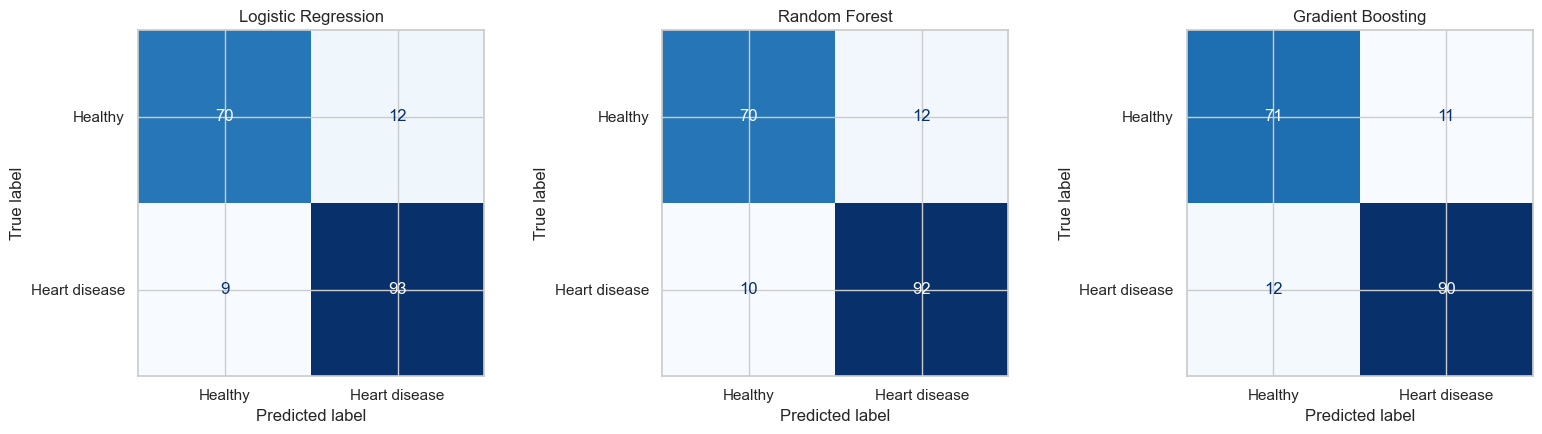

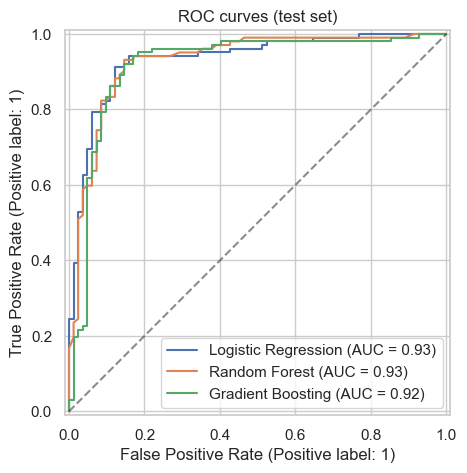

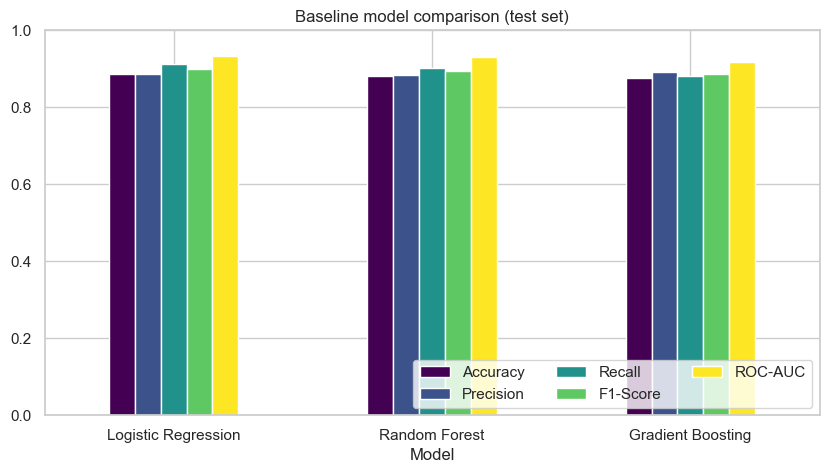

Logistic Regression
               precision    recall  f1-score   support

      Healthy       0.89      0.85      0.87        82
Heart disease       0.89      0.91      0.90       102

     accuracy                           0.89       184
    macro avg       0.89      0.88      0.88       184
 weighted avg       0.89      0.89      0.89       184

Random Forest
               precision    recall  f1-score   support

      Healthy       0.88      0.85      0.86        82
Heart disease       0.88      0.90      0.89       102

     accuracy                           0.88       184
    macro avg       0.88      0.88      0.88       184
 weighted avg       0.88      0.88      0.88       184

Gradient Boosting
               precision    recall  f1-score   support

      Healthy       0.86      0.87      0.86        82
Heart disease       0.89      0.88      0.89       102

     accuracy                           0.88       184
    macro avg       0.87      0.87      0.87       184
 weig

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["Healthy", "Heart disease"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("results/confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.5); ax.set_title("ROC curves (test set)")
plt.savefig("results/roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

baseline.plot(kind="bar", figsize=(10, 5), rot=0, colormap="viridis")
plt.title("Baseline model comparison (test set)"); plt.ylim(0, 1); plt.legend(loc="lower right", ncol=3)
plt.savefig("results/baseline_bar.png", dpi=150, bbox_inches="tight"); plt.show()

for name, m in models.items():
    print("=" * 60); print(name)
    print(classification_report(y_test, m.predict(X_test), target_names=["Healthy", "Heart disease"]))

In [15]:
best_name = baseline["ROC-AUC"].idxmax()
print("Best baseline by ROC-AUC:", best_name)
print("Best baseline by F1     :", baseline["F1-Score"].idxmax())

Best baseline by ROC-AUC: Logistic Regression
Best baseline by F1     : Logistic Regression


**Discussion (write after running):** compare the models on ROC-AUC, recall and F1. The test set is small (about 184 rows), so differences of 1-2 points are within noise; use the cross-validated ROC-AUC (mean ± std) as supporting evidence.

## 7. Hyperparameter Tuning (RandomizedSearchCV)

In [16]:
param_dists = {
    "Logistic Regression": {"clf__C": np.logspace(-3, 2, 20)},
    "Random Forest": {"clf__n_estimators": [200, 300, 500], "clf__max_depth": [None, 4, 6, 10],
                      "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3, 0.5]},
    "Gradient Boosting": {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [2, 3, 4],
                          "clf__learning_rate": [0.01, 0.03, 0.05, 0.1], "clf__subsample": [0.7, 0.85, 1.0],
                          "clf__min_samples_leaf": [1, 3, 5, 10]},
}
search = RandomizedSearchCV(clone(models[best_name]), param_dists[best_name], n_iter=25, scoring="roc_auc",
                            cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
tuned = search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'clf__C': np.float64(0.23357214690901212)}
Best CV ROC-AUC: 0.9228


## 8. Ensemble Learning (Voting and Stacking)

                                Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                         
Logistic Regression (baseline)    0.8859     0.8857  0.9118    0.8986   0.9329
Logistic Regression (tuned)       0.8859     0.8857  0.9118    0.8986   0.9335
Voting (soft)                     0.8967     0.9109  0.9020    0.9064   0.9357
Stacking                          0.8913     0.9020  0.9020    0.9020   0.9358


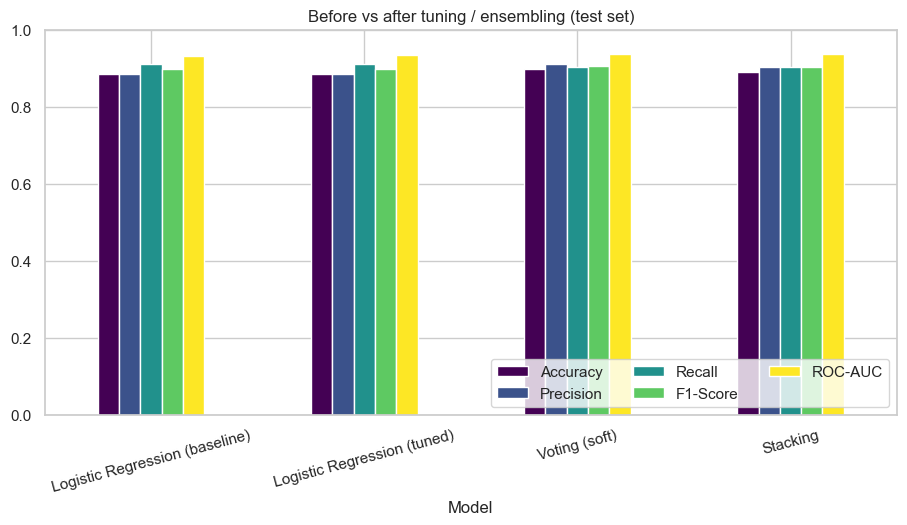

In [17]:
estimators = [(n.replace(" ", "_"), clone(m)) for n, m in models.items()]
voting = VotingClassifier(estimators=estimators, voting="soft", n_jobs=-1).fit(X_train, y_train)
stacking = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(max_iter=1000),
                              cv=5, n_jobs=-1).fit(X_train, y_train)

final_rows = [evaluate(f"{best_name} (baseline)", models[best_name], X_test, y_test),
              evaluate(f"{best_name} (tuned)", tuned, X_test, y_test),
              evaluate("Voting (soft)", voting, X_test, y_test),
              evaluate("Stacking", stacking, X_test, y_test)]
final = pd.DataFrame(final_rows).set_index("Model").round(4)
print(final); final.to_csv("results/before_after_improvement.csv")

final.plot(kind="bar", figsize=(11, 5), rot=15, colormap="viridis")
plt.title("Before vs after tuning / ensembling (test set)"); plt.ylim(0, 1); plt.legend(loc="lower right", ncol=3)
plt.savefig("results/improvement_bar.png", dpi=150, bbox_inches="tight"); plt.show()

**Discussion (write after running):** state whether tuning or ensembling improved ROC-AUC and F1, by how much, and whether the gain is larger than the noise expected on a small test set.

## 9. Feature Importance

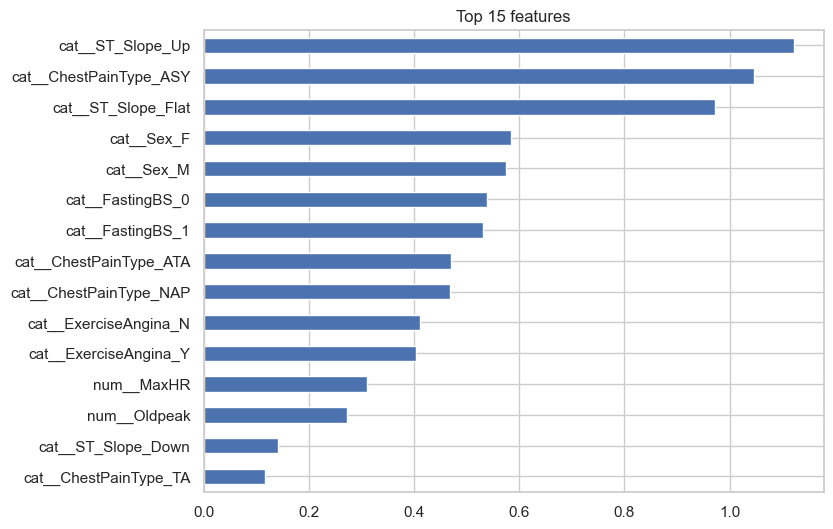

In [18]:
clf = tuned.named_steps["clf"]
names = tuned.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=names)
else:
    imp = pd.Series(np.abs(clf.coef_[0]), index=names)
imp.nlargest(15).sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 features")
plt.savefig("results/feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

## 10. Save the final model and verify it reloads

In [19]:
candidates = {f"{best_name} (tuned)": tuned, "Voting (soft)": voting, "Stacking": stacking}
winner = max(candidates, key=lambda k: f1_score(y_test, candidates[k].predict(X_test)))
print("Final model selected (highest test F1):", winner)
final_model = candidates[winner]

meta = {"num_cols": num_cols, "cat_cols": cat_cols, "model_name": winner,
        "choices": {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols},
        "num_ranges": {c: [float(X[c].min()), float(X[c].max())] for c in num_cols},
        "num_defaults": {c: float(X[c].median()) for c in num_cols},
        "num_is_int": {c: bool((df[c].dropna() % 1 == 0).all()) for c in num_cols}}
joblib.dump(final_model, "heart_model.joblib")
joblib.dump(meta, "app_meta.joblib")

# Reload check: the saved file must give identical predictions
reloaded = joblib.load("heart_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test), final_model.predict_proba(X_test))
print("Saved and reloaded OK: heart_model.joblib, app_meta.joblib")

Final model selected (highest test F1): Voting (soft)
Saved and reloaded OK: heart_model.joblib, app_meta.joblib
